<a href="https://colab.research.google.com/github/U-mar-404/AIPDD-lab04/blob/main/aipdd_lab04_(Wav).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Speech AI for Beginners
### Upload a WAV file → look at it → turn it into text

## Step 1: Install the tools

In [ ]:
!pip -q install librosa matplotlib transformers

## Step 2: Import the tools
"Importing" means telling Python which libraries we want to use.

In [ ]:
import numpy as np                  # works with lists of numbers (our audio)
import matplotlib.pyplot as plt     # draws graphs
import librosa                      # audio analysis
import librosa.display              # draws spectrograms
from IPython.display import Audio, display   # plays audio in the notebook
from google.colab import files      # lets us upload a file from your computer
from transformers import pipeline   # loads the Whisper AI model

print("All tools imported ✅")

All tools imported ✅


## Step 3: Upload your WAV file

In [ ]:
uploaded = files.upload()                      # a file picker will appear

# Get the name of the file you chose
wav_file = list(uploaded.keys())[0]
print("Uploaded:", wav_file)

Saving OSR_us_000_0034_8k.wav to OSR_us_000_0034_8k.wav
Uploaded: OSR_us_000_0034_8k.wav


## Step 4: Listen to your file
Press play to check that the audio was uploaded correctly.

In [ ]:
display(Audio(wav_file))

## Step 5: Load the audio into Python
Sound is stored as a long list of numbers called **samples**.
- **Sampling rate** = how many samples are taken every second (measured in Hz).
- **Duration** = number of samples ÷ sampling rate.

In [ ]:
audio, sample_rate = librosa.load(wav_file, sr=None, mono=True)

print("Sampling rate:", sample_rate, "Hz")
print("Number of samples:", len(audio))
print("Duration:", round(len(audio) / sample_rate, 2), "seconds")

Sampling rate: 8000 Hz
Number of samples: 284383
Duration: 35.55 seconds


## Step 6: Draw the waveform
The waveform shows the **loudness (amplitude)** of your voice over time.
Big bumps = loud sounds. Flat lines = silence.

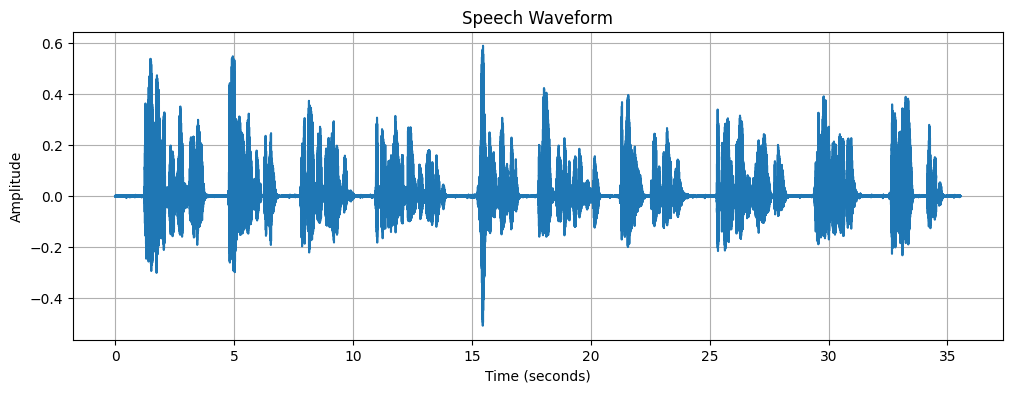

In [ ]:
# Make a list of time values (in seconds), one for each sample
time = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(time, audio)
plt.title("Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

## Step 7: Draw the spectrogram

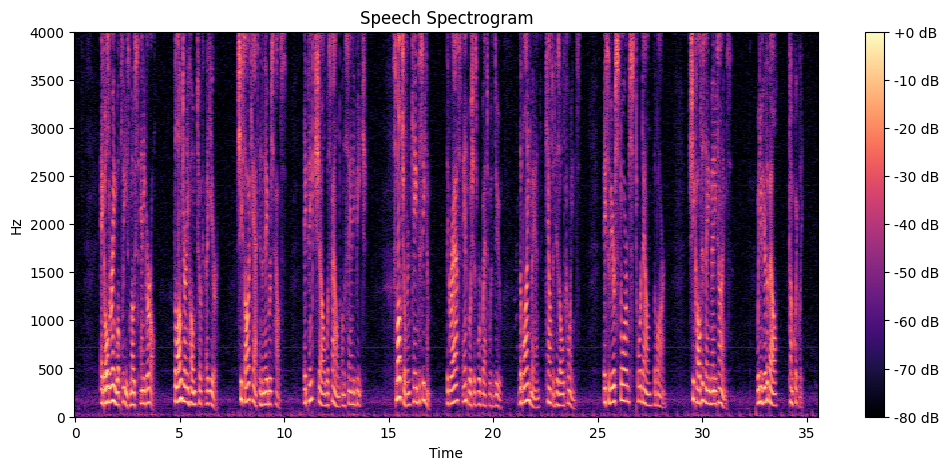

In [ ]:
# Break the audio into small pieces and measure the frequencies in each piece
stft = librosa.stft(audio)

# Convert the numbers to decibels (dB) so the picture is easier to read
spectrogram = librosa.amplitude_to_db(np.abs(stft), ref=np.max)

plt.figure(figsize=(12, 5))
librosa.display.specshow(spectrogram, sr=sample_rate, x_axis="time", y_axis="hz")
plt.colorbar(format="%+2.0f dB")
plt.title("Speech Spectrogram")
plt.show()

## Step 8: Preprocess the audio
AI models expect audio in a specific format. We will:
1. **Resample** to 16,000 Hz (the rate Whisper was trained on)
2. Make sure it is **mono** (one channel)
3. **Normalize** it so the volume is consistent

In [ ]:
target_rate = 16000

# Load again, this time converting to 16,000 Hz mono
clean_audio, clean_rate = librosa.load(wav_file, sr=target_rate, mono=True)

# Scale the volume so the loudest part reaches the maximum level
clean_audio = librosa.util.normalize(clean_audio)

print("New sampling rate:", clean_rate, "Hz")
print("Duration:", round(len(clean_audio) / clean_rate, 2), "seconds")

New sampling rate: 16000 Hz
Duration: 35.55 seconds


## Step 9: Load the Whisper AI model

In [ ]:
speech_to_text = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny.en"
)
print("Model loaded ✅")

config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

Model loaded ✅


## Step 10: Convert speech to text
Now we give the cleaned audio to the model and print what it heard.

In [ ]:
result = speech_to_text({"raw": clean_audio, "sampling_rate": clean_rate}, return_timestamps=True)

print("What the AI heard:")
print(result["text"])

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


What the AI heard:
 A golden ring will please most any girl. The long journey home took a year. She saw a cat in the neighbor's house. A pink shell was found on the sandy beach. Small children came to see him. The grass and bushes were wet with dew. The blind man counted his old coins. A severe storm tore down the barn. He called his name many times. When you hear the bell, come quickly.
